# Continuidad de negocio: reportes de amenazas físicas

## Resumen

**Decisión:** orientar la selección de escenarios de continuidad para instalaciones en Colombia. Los datos resumen filas administrativas de 2025 para cuatro grupos de amenazas hidrológicas y geológicas. Las cifras son reportes, no eventos únicos ni interrupciones de una empresa.

**Resultado del corte:** El agregado contiene 2.309 filas; movimiento en masa registra 1.273 e inundación 721.

## Contexto y método

Comparación descriptiva para apoyar preguntas de gestión. No se identifica causalidad ni se valida un modelo productivo.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})

## Datos y procedencia

Fuente primaria: [UNGRD, Emergencias V2](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Emergencias-UNGRD-V2/2343-nuqp). Se usa un agregado reproducible del repositorio con extracción el 11-11-2026, fuente actualizada el 22-09-2026. El [manifiesto](../../../07-financial-and-construction-risk-lab/02-construction-enterprise-risk/10-climate-flood-and-physical-risk/data/official/ungrd-2025/source_quality_manifest.json) documenta 557 combinaciones fecha-municipio-tipo repetidas y coordenadas en su mayoría vacías. **No** usar como frecuencia independiente de eventos o cobertura geográfica de activos.

In [2]:
path = repo / '03-financial-risk/07-financial-and-construction-risk-lab/02-construction-enterprise-risk/10-climate-flood-and-physical-risk/data/official/ungrd-2025/event_type_summary_2025.csv'
df = pd.read_csv(path)
assert set(df.columns) == {'event_group', 'report_rows'}
df = df.sort_values('report_rows', ascending=False)
df['proporcion_reportes'] = df['report_rows'] / df['report_rows'].sum()
print('Filas de reporte:', df.report_rows.sum(), '| SHA-256 agregado:', hashlib.sha256(path.read_bytes()).hexdigest())
display(df)

Filas de reporte: 2309 | SHA-256 agregado: 72511b0d663bd741521e73981a6a63ce67c69f83a0d411d1b28b97ee00918cdb


,event_group,report_rows,proporcion_reportes
2,Movimiento en masa,1273,0.551321
3,Inundación,721,0.312256
1,Creciente súbita,260,0.112603
0,Avenida torrencial,55,0.023820


## Resultados

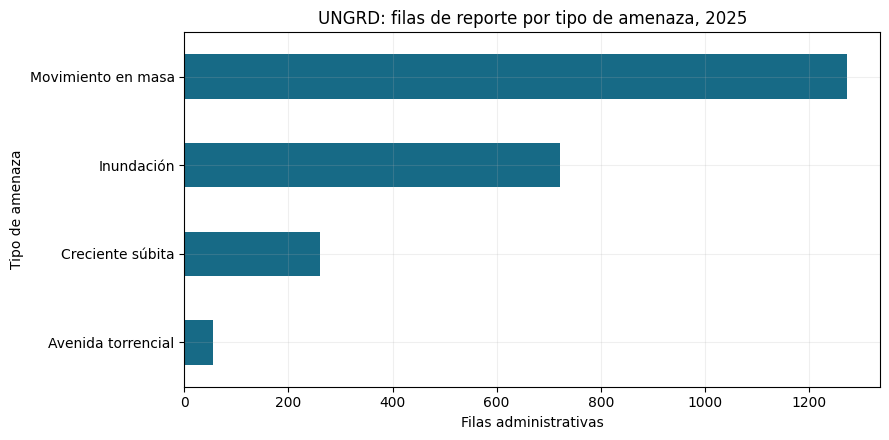

In [3]:
ax=df.plot.barh(x='event_group', y='report_rows', legend=False, color='#176a86'); ax.invert_yaxis(); ax.set(title='UNGRD: filas de reporte por tipo de amenaza, 2025', xlabel='Filas administrativas', ylabel='Tipo de amenaza'); plt.tight_layout(); plt.show()

### Verificaciones del agregado y concentración de reportes

Cada fila del archivo es una categoría de reporte; el denominador de las proporciones es el total de filas administrativas representadas, no el número de eventos únicos.

In [4]:
assert df.event_group.notna().all() and df.event_group.is_unique
assert df.report_rows.notna().all() and (df.report_rows >= 0).all() and df.report_rows.sum() > 0
assert abs(df.proporcion_reportes.sum() - 1) < 1e-10
df['proporcion_pct'] = 100 * df.proporcion_reportes
print(f"Las dos categorías más frecuentes reúnen {df.proporcion_pct.iloc[:2].sum():.1f}% de los reportes del agregado.")
display(df[['event_group','report_rows','proporcion_pct']].round(2))

Las dos categorías más frecuentes reúnen 86.4% de los reportes del agregado.


,event_group,report_rows,proporcion_pct
2,Movimiento en masa,1273,55.13
3,Inundación,721,31.23
1,Creciente súbita,260,11.26
0,Avenida torrencial,55,2.38


Este agregado cubre solo cuatro grupos seleccionados y 2025. El mayor peso puede resultar de diferencias de exposición o reporte; no autoriza ordenar ubicaciones individuales ni comparar el riesgo total de otras amenazas.

## Variante: cobertura de escenarios y concentración

Una selección basada en las dos categorías con más **filas** cubre una fracción del agregado observado; otra que dedique el mismo esfuerzo a cada una de las cuatro categorías cubriría dos de las cuatro sin considerar frecuencias. Son criterios de selección, no probabilidades futuras. El inverso de la suma de proporciones al cuadrado resume el número efectivo de categorías en esta tabla. La [guía NIST SP 800-34 Rev. 1](https://csrc.nist.gov/pubs/sp/800/34/r1/upd1/final) propone identificar requisitos y prioridades de continuidad; la [UNDRR](https://www.undrr.org/building-risk-knowledge/disaster-data) recomienda desagregar y georreferenciar datos de pérdidas. Este resumen no contiene ubicaciones de activos ni impactos para hacer un BIA.

In [5]:
shares = df.proporcion_reportes
hhi = (shares ** 2).sum()
effective = 1 / hhi
print(f'Categorías: {len(df)} | número efectivo por concentración: {effective:.2f}')
print(f'Dos categorías con mayor conteo: {100 * shares.iloc[:2].sum():.1f}% de las filas del corte')
print(f'Dos categorías con igual prioridad: {100 * 2 / len(df):.1f}% de las categorías, no de las filas')
assert 1 <= effective <= len(df) + 1e-9

df[['event_group', 'report_rows', 'proporcion_pct']].assign(
    cobertura_acumulada_pct=df.proporcion_pct.cumsum()).round(2)

Categorías: 4 | número efectivo por concentración: 2.41
Dos categorías con mayor conteo: 86.4% de las filas del corte
Dos categorías con igual prioridad: 50.0% de las categorías, no de las filas


,event_group,report_rows,proporcion_pct,cobertura_acumulada_pct
2,Movimiento en masa,1273,55.13,55.13
3,Inundación,721,31.23,86.36
1,Creciente súbita,260,11.26,97.62
0,Avenida torrencial,55,2.38,100.00


## Interpretación y límites

La selección de escenarios requiere geolocalización verificada de instalaciones, activos críticos y tiempos de recuperación. La distribución refleja captura administrativa y no mide probabilidades, daños ni efectividad del plan.

**Reproducción:** desde este repositorio ejecutar `python -m jupyter nbconvert --execute --to notebook --inplace 01_contexto_ungrd.ipynb` en la carpeta del proyecto; requiere Python, pandas, matplotlib, nbformat, nbclient e ipykernel.